# **Laboratorio de Procesamiento Digital de Imágenes (PDI)**

Pablo Andrés Villarreal Cárdenas - 2043233

Alan Zahir Lopez Rodriguez - 2103115

# **Práctica 5. Tipos de Traslación de Imágenes**

**Importación de librerías**

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

Se realiza la importación de librerías necesarias para llevar a cabo la práctica. OpenCV (cv2) se encarga del procesamiento y las transformaciones realizadas en las imágenes, mientras que Numpy es utilizado para la manipulación de matrices numéricas y Matplotlib para lograr visualizar los resultados de cada transformación.

Asimismo, para todos los ejercicios especificados en esta práctica, la imagen seleccionada se va a cargar en escala de grises por medio de la función "cv2.imread()" para cargar la imagen y "cv2.IMREAD_GRAYSCALE" para que se encuentre en escala de grises.

# **Parte I.- Transformaciones Geometricas**

**Ejercicio 1: Traslación básica de imagen**

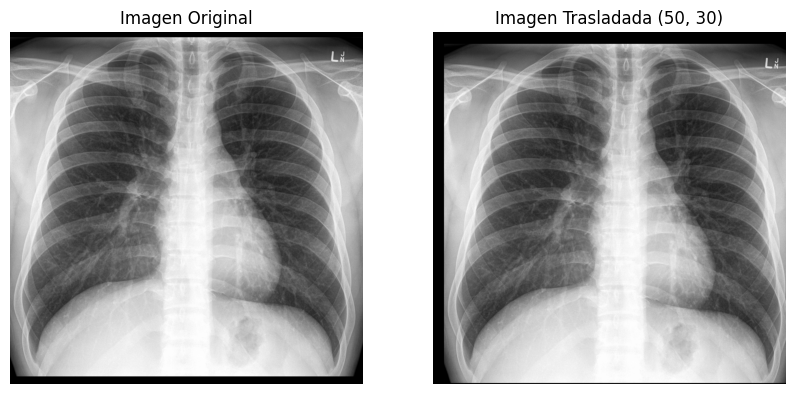

In [ ]:
# Cargar la imagen en escala de grises
imagen = cv2.imread("/content/normal-frontal-chest-x-ray.jpeg",
                    cv2.IMREAD_GRAYSCALE)

# Dimensiones de la imagen
alto, ancho = imagen.shape

# Definir la matriz de traslación
tx, ty = 50, 30 # Mueve la imagen 50 px a la derecha y 30 px hacia abajo
M = np.float32([[1, 0, tx],
                [0, 1, ty]])

# Aplicar la transformación afín
imagen_trasladada = cv2.warpAffine(imagen, M, (ancho, alto))

# Mostrar imágenes
plt.figure(figsize = (10, 5))
plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap = "gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_trasladada, cmap = "gray")
plt.title("Imagen Trasladada (50, 30)")
plt.axis("off")

plt.show()

Para este ejercicio, primeramente se obtienen las dimensiones de la imagen por medio de ".shape" que corresponden al alto y ancho.

Después, en las variables "tx" y "ty" se establecen los valores de desplazamiento de la imagen, asignando un valor de 50 pixeles en el eje "x" y 30 píxeles en el eje "y". Luego en la matriz de traslación son colocados dichos valores.

La traslación es aplicada a la imagen por medio de la función "cv2.warpAffine()", donde haciendo uso de la matriz de traslación "M" y las dimensiones de la imagen, es que se obtiene la imagen desplazada.

Por último, a través de matplotlib es que se pueden comparar ambas imágenes para verificar si la transformación se aplicó correctamente.

**Ejercicio 2: Traslación con valores decimales**

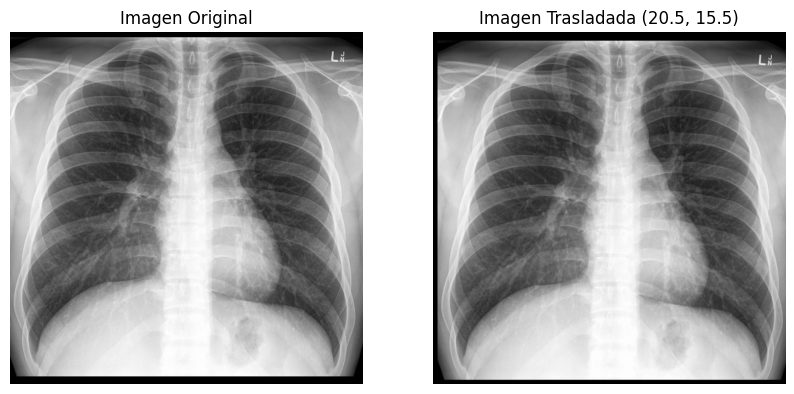

In [ ]:
# Cargar la imagen en escala de grises
imagen = cv2.imread("/content/normal-frontal-chest-x-ray.jpeg",
                    cv2.IMREAD_GRAYSCALE)

# Dimensiones de la imagen
alto, ancho = imagen.shape

# Definir la matriz de traslación con valores decimales
tx, ty = 20.5, 15.5 # Mueve la imagen 20.5 px a la derecha y 15.5 px hacia abajo
M = np.float32([[1, 0, tx],
                [0, 1, ty]])

# Aplicar la traslación con interpolación
imagen_trasladada = cv2.warpAffine(imagen, M, (ancho, alto),
                                   flags = cv2.INTER_LINEAR)

# Mostrar imágenes
plt.figure(figsize = (10, 5))
plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap = "gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_trasladada, cmap = "gray")
plt.title("Imagen Trasladada (20.5, 15.5)")
plt.axis("off")

plt.show()

Se obtienen las dimensiones de la imagen mediante ".shape", guardando dichos valores nuevamente como alto y ancho.

A diferencia del ejercicio anterior, los valores que se establecen en las variables "tx" y "ty" son ahora un desplazamiento de 20.5 píxeles en el eje "x" y 15.5 píxeles en el eje "y". Asimismo, la matriz de traslación se construye colocando dichas variables.

La traslación de la imagen se hace con la función "cv2.warpAffine()", colocando no solo la matriz de traslación, sino también las dimensiones al igual que en el ejercicio 1. Sin embargo, se especifica también el método de interpolación "cv2.INTER_LINEAR" que se encarga de calcular los valores de los píxeles de la imagen resultante ya que se utilizaron valores decimales para desplazar a esta.

Por último, se utiliza matplotlib para realizar la comparación entre la imagen original y la imagen trasladada (20.5, 15.5) píxeles.

**Ejercicio 3: Traslación + Rotación**

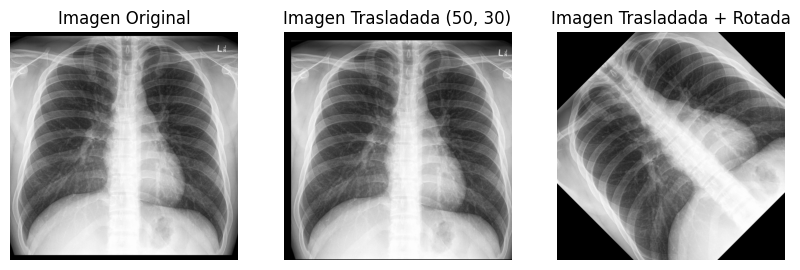

In [ ]:
# Cargar la imagen en escala de grises
imagen = cv2.imread("/content/normal-frontal-chest-x-ray.jpeg",
                    cv2.IMREAD_GRAYSCALE)

# Dimensiones de la imagen
alto, ancho = imagen.shape

# Definir traslación (50 px a la derecha y 30 px hacia abajo)
tx, ty = 50, 30
M = np.float32([[1, 0, tx],
                [0, 1, ty]])

# Aplicar traslación a la imagen
imagen_trasladada = cv2.warpAffine(imagen, M, (ancho, alto))

# Definir rotación de 45° alrededor del centro de la imagen
angulo = 45
centro = (ancho // 2, alto // 2) # Centro de la imagen
escala = 1.0 # Escala sin cambios

M_rotacion = cv2.getRotationMatrix2D(centro, angulo, escala)

# Aplicar rotación en la imagen trasladada
imagen_resultante = cv2.warpAffine(imagen_trasladada, M_rotacion, (ancho, alto))

# Mostrar imágenes
plt.figure(figsize = (10, 5))
plt.subplot(1, 3, 1)
plt.imshow(imagen, cmap = "gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(imagen_trasladada, cmap = "gray")
plt.title("Imagen Trasladada (50, 30)")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(imagen_resultante, cmap = "gray")
plt.title("Imagen Trasladada + Rotada")
plt.axis("off")

plt.show()

Al igual que en los ejercicios previos, se obtienen las dimensiones de la imagen a través ".shape", guardando dichos valores como alto y ancho.

Se aplica una traslación de (50, 30) píxeles de la misma forma que en el ejercicio 1 haciendo uso de la función "cv2.warpAffine()", con la diferencia que ahora la imagen resultante pasará por una rotación.

Para aplicar una rotación a la imagen trasladada, primero se establece el ángulo que se desea, en este caso de 45 grados alrededor del centro de la imagen. Se calcula la matriz de rotación con la función "cv2.getRotationMatrix2D()" estableciendo el centro, el ángulo deseado y la escala (1.0 o 100%). Después, se aplica nuevamente la función "cv2.warpAffine" pero ahora a la imagen trasladada para aplicar la matriz de rotación, resultando en una imagen con ambas transformaciones en ella.

Para finalizar, utilizando matplotlib se hace la comparación entre 3 imágenes: la original, la trasladada (50, 30) píxeles y la rotada 45 grados. Pudiendo observar que las transformaciones se aplicaron correctamente.

**Ejercicio 4: Traslación + Rotación + Escalado**

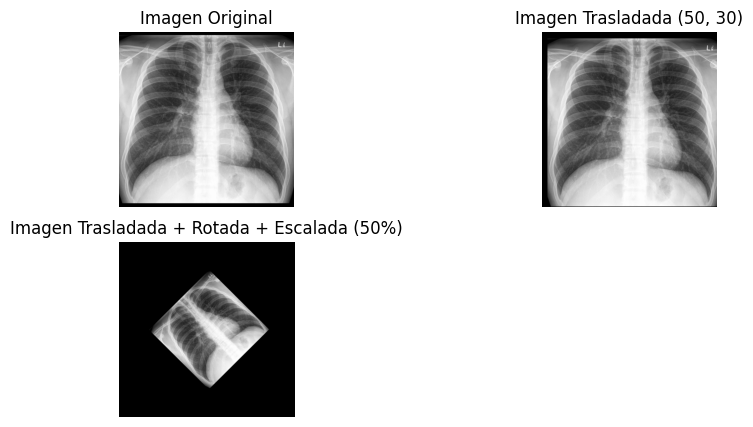

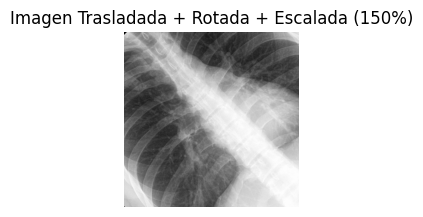

In [ ]:
# Cargar la imagen en escala de grises
imagen = cv2.imread("/content/normal-frontal-chest-x-ray.jpeg",
                    cv2.IMREAD_GRAYSCALE)

# Dimensiones de la imagen
alto, ancho = imagen.shape

# Definir traslación (50 px a la derecha y 30 px hacia abajo)
tx, ty = 50, 30
M = np.float32([[1, 0, tx],
                [0, 1, ty]])

# Aplicar traslación a la imagen
imagen_trasladada = cv2.warpAffine(imagen, M, (ancho, alto))

# Definir rotación de 45° alrededor del centro de la imagen
angulo = 45
centro = (ancho // 2, alto // 2) # Centro de la imagen
escala = 0.5 # Aplicar un escalado de 0.5

escala_2 = 1.5 # A otra imagen aplicar un escalado de 1.5

M_rotacion = cv2.getRotationMatrix2D(centro, angulo, escala)
M_rotacion_2 = cv2.getRotationMatrix2D(centro, angulo, escala_2)

# Aplicar rotación y escalado a ambas imágenes
imagen_resultante = cv2.warpAffine(imagen_trasladada, M_rotacion,
 (ancho, alto))
imagen_resultante_2 = cv2.warpAffine(imagen_trasladada, M_rotacion_2,
 (ancho, alto))

# Mostrar imágenes
plt.figure(figsize = (10, 5))
plt.subplot(2, 2, 1)
plt.imshow(imagen, cmap = "gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(2, 2, 2)
plt.imshow(imagen_trasladada, cmap = "gray")
plt.title("Imagen Trasladada (50, 30)")
plt.axis("off")

plt.subplot(2, 2, 3)
plt.imshow(imagen_resultante, cmap = "gray")
plt.title("Imagen Trasladada + Rotada + Escalada (50%)")
plt.axis("off")


plt.figure(figsize = (10, 5))
plt.subplot(2, 2, 4)
plt.imshow(imagen_resultante_2, cmap = "gray")
plt.title("Imagen Trasladada + Rotada + Escalada (150%)")
plt.axis("off")

plt.show()

Las dimensiones de la imagen se obtienen a través de ".shape", almacenando los valores como ancho y alto.

Nuevamente aplicamos una traslación de (50, 30) píxeles en el eje x y eje y respectivamente. Estableciendo posteriormente una rotación de 45 grados.

Lo más resaltable es que se definen 2 variables para escalar la imagen, una con 0.5 (50%) y la otra con 1.5 (150%) para lograr analizar cómo puede cambiar una imagen al ser escalada de forma distinta. Entonces, se realizan 2 matrices de rotación con la función "cv2.getRotationMatrix2D()", una correspondiente a cada valor de escalado.

Con ambas matrices de rotación, se aplican de manera independiente por medio de la función "cv2.warpAffine()", lo que nos permite obtener 2 imágenes distintas. Ambas se encuentran desplazadas (50, 30) píxeles y rotadas 45 grados, pero una de ellas con un escalamiento de 0.5 y la otra de 1.5.

A través de matplotlib es que podemos visualizar todas las transformaciones aplicadas. Desde la traslación hacia el escalamiento. Observando los resultados, podemos ver que la imagen escalada a 1.5 se sale de la cuadrícula mientras que aquella en 0.5 pierde información al ser tan pequeña.

**Ejercicio 5: Transformación Afin y Radial**

(np.float64(-0.5), np.float64(1599.5), np.float64(1599.5), np.float64(-0.5))

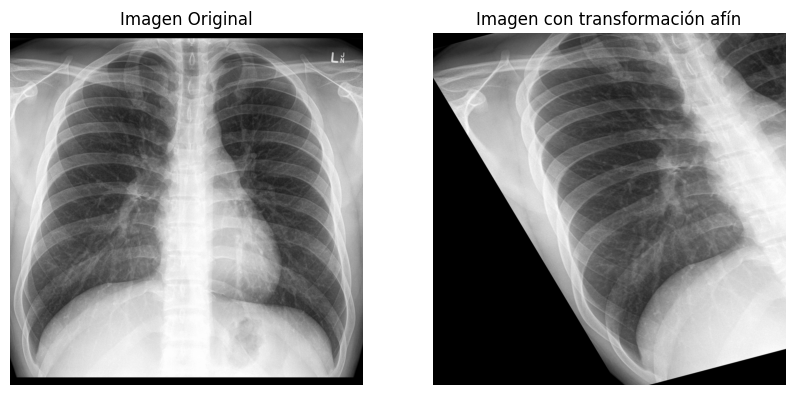

In [3]:
# Cargar la imagen en escala de grises
imagen = cv2.imread("/content/normal-frontal-chest-x-ray.jpeg",
                    cv2.IMREAD_GRAYSCALE)

# Definir puntos originales
pts1 = np.float32([[50, 50], [200, 50], [50, 200], [200, 200]])

# Definir nuevos puntos transformados
pts2 = np.float32([[10, 100], [200, 50], [100, 250], [290, 200]])

# Obtener matriz de transformación afín
M, _ = cv2.estimateAffine2D(pts1, pts2)

# Aplicar la transformación
filas, columnas = imagen.shape
imagen_transformada = cv2.warpAffine(imagen, M, (columnas, filas))

# Mostrar imágenes
plt.figure(figsize = (10, 5))
plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap = "gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_transformada, cmap = "gray")
plt.title("Imagen con transformación afín")
plt.axis("off")

Para aplicar una transformación afín a la imagen, se definieron dos conjuntos de cuatro puntos, "pts1" representa los puntos de referencia de la imagen original, mientras que "pts2" los nuevos puntos a los que se desea llevar cada uno.

Debido a que la función "cv2.getAffineTransform()" solo acepta tres puntos de referencia, se optó por utilizar "cv2.estimateAffine2D()" para obtener la matriz de transformación afín. Posteriormente, fue aplicada a la imagen a través de "cv2.warpAffine()" y  por medio de matplotlib es que se logró visualizar la comparación entre la imagen original y la imagen con una transformación afín aplicada.

(np.float64(-0.5), np.float64(1599.5), np.float64(1599.5), np.float64(-0.5))

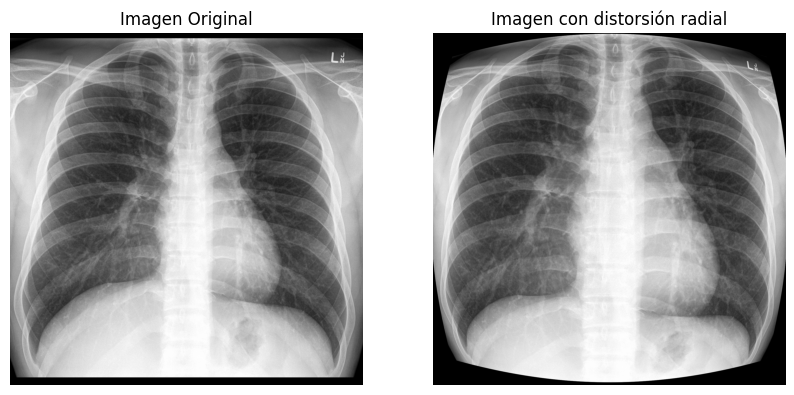

In [4]:
# Matriz de calibración de la cámara y coeficientes de distorsión
h, w = imagen.shape[:2]
K = np.array([[w / 2, 0, w / 2], [0, w / 2, h / 2], [0, 0, 1]])  # Matriz intrínseca
dist_coef = np.array([0.5, 0.1, 0, 0, 0]) # Coeficientes de distorsión radial

# Corregir la distorsión radial
new_K, roi = cv2.getOptimalNewCameraMatrix(K, dist_coef, (w, h), 1, (w, h))
imagen_corregida = cv2.undistort(imagen, K, dist_coef, None, new_K)

# Mostrar imágenes
plt.figure(figsize = (10, 5))
plt.subplot(1, 2, 1)
plt.imshow(imagen, cmap = "gray")
plt.title("Imagen Original")
plt.axis("off")

plt.subplot(1, 2, 2)
plt.imshow(imagen_corregida, cmap = "gray")
plt.title("Imagen con distorsión radial")
plt.axis("off")

Asimismo, como parte del desarrollo para el ejercicio 5, se definió una matriz intrínseca "K" que contiene la distancia focal y el centro óptico de la imagen, para definirla, se utilizaron las dimensiones de la imagen. Junto a esa matriz, se definió un vector de coeficientes de distorsión, en donde los dos primeros valores se encargan de controlar la distorsión radial, mientras que los otros dos se utilizan para una distorsión tangencial.

Por medio de "cv2.getOptimalNewCameraMatrix()" es que se calculó una nueva matriz que conserva todos los píxeles de la imagen. Después, por medio de "cv2.undistort()" es que se remapeó cada píxel en base a su distancia del centro, provocando el efecto de ojo de pez. La imagen resultante también se visualiza con ayuda de matplotlib.